In [101]:
import numpy as np
import pandas as pd
import duckdb
from pandas.tseries.holiday import USFederalHolidayCalendar

In [102]:
#Files#
CentralParkWeather = pd.read_csv("CentralPark.csv")
JFKWeather = pd.read_csv("JFK.csv")
Complaints = pd.read_csv("311ServiceRequests.csv")


In [103]:
CentralParkWeather.head()

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_ATTRIBUTES,SNOW,SNOW_ATTRIBUTES,...,WT17,WT17_ATTRIBUTES,WT18,WT18_ATTRIBUTES,WT19,WT19_ATTRIBUTES,WT21,WT21_ATTRIBUTES,WT22,WT22_ATTRIBUTES
0,USW00094728,2020-01-01,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,USW00094728,2020-01-02,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,USW00094728,2020-01-03,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",38,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,USW00094728,2020-01-04,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",69,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,USW00094728,2020-01-05,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0,"T,,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [104]:
#Looking for NaNs, nulls 
pd.set_option("display.max_rows", None)
summary = pd.DataFrame({
    "null_count": CentralParkWeather.isna().sum(),
    "null_pct": (CentralParkWeather.isna().mean() * 100).round(2),
}).sort_values("null_pct", ascending=False)

summary

,null_count,null_pct
ACMH,2436,100.00
ACMH_ATTRIBUTES,2436,100.00
ACSH,2436,100.00
ACSH_ATTRIBUTES,2436,100.00
EVAP,2436,100.00
EVAP_ATTRIBUTES,2436,100.00
TOBS_ATTRIBUTES,2436,100.00
TOBS,2436,100.00
PSUN,2436,100.00
PSUN_ATTRIBUTES,2436,100.00


In [105]:
#Initally, all of the attributes above that have a null percent of 100.00 will be dropped since they contain no data.
#A second group of columns that have some data, but not enough or not useful, is dropped as well.

# Each NOAA measurement column (e.g. "TAVG") has a matching "_ATTRIBUTES" column
# (e.g. "TAVG_ATTRIBUTES") with its flags, so each column is dropped together with its partner.

# ======================= PART 1: 100% NULL COLUMNS =======================

# --- Temperature ---
# TOBS (temperature at observation time)
# were never recorded. Compute average temperature later as (TMAX + TMIN) / 2.
temperature_cols = ["TOBS"]

# --- Cloud cover ---
# ACMH / ACSH: average cloudiness, midnight-to-midnight and sunrise-to-sunset.
cloud_cols = ["ACMH", "ACSH"]

# --- Sunshine ---
# PSUN: percent of possible sunshine.
sunshine_cols = ["PSUN"]

# --- Evaporation ---
# DAEV: number of days in a multi-day evaporation total
# MDEV: multi-day evaporation total
# EVAP: daily pan evaporation
evaporation_cols = ["DAEV", "MDEV", "EVAP"]

# --- Multi-day snowfall and wind totals ---
# DASF / MDSF: number of days and total for multi-day snowfall
# DAWM / MDWM: number of days and total for multi-day wind movement
multiday_cols = ["DASF", "MDSF", "DAWM", "MDWM"]

# --- Wind ---
# FMTM: time of the fastest mile or fastest 1-minute wind
# WDF1 / WSF1: direction and speed of the fastest 1-minute wind
# WDFG / WSFG: direction and speed of the peak gust
# WDFM / WSFM: direction and speed of the fastest mile
# WDMV: 24-hour wind movement
wind_cols = ["FMTM", "WDF1", "WSF1", "WDFG", "WSFG", "WDFM", "WSFM", "WDMV"]

# --- Snow water equivalent ---
# WESD: water equivalent of snow on the ground.
snow_water_cols = ["WESD"]

# --- Weather-type flags ---
# A WT** column holds 1 on days the event happened and is blank otherwise.
# These were never flagged at this station, so they carry no information.
#   WT07 dust/sand          WT11 high winds       WT13 mist
#   WT14 drizzle            WT15 freezing drizzle WT16 rain
#   WT17 freezing rain      WT18 snow             WT19 unknown precipitation
#   WT21 ground fog         WT22 ice fog
weather_type_cols = ["WT07", "WT11", "WT13", "WT14", "WT15", "WT16",
                     "WT17", "WT18", "WT19", "WT21", "WT22"]

empty_measurements = (temperature_cols + cloud_cols + sunshine_cols +
                      evaporation_cols + multiday_cols + wind_cols +
                      snow_water_cols + weather_type_cols)

# ============== PART 2: COLUMNS WITH SOME DATA, DROPPED BY CHOICE ==============

# --- Nearly empty ---
# TSUN: daily minutes of sunshine. Only 2 of 2,436 days have a value (both 0).
# PGTM: time of day of the peak gust. Only recorded on 69 days (2024-2025),
#       and a time of day is not useful for comparing against daily 311 counts.
nearly_empty_cols = ["TSUN", "PGTM"]

# --- Wind direction ---
# WDF2 / WDF5: direction of the fastest 2-minute and 5-second wind (degrees).
# Not needed for this analysis, and directions are angles that cannot be averaged
# normally (the average of 350 and 10 degrees is 0, not 180).
wind_direction_cols = ["WDF2", "WDF5"]


chosen_measurements = nearly_empty_cols + wind_direction_cols

# ============================ DROP BOTH GROUPS ============================

# --- Safety check: confirm every Part 1 column is really 100% null before dropping ---
empty_to_drop = empty_measurements + [c + "_ATTRIBUTES" for c in empty_measurements]
not_empty = [c for c in empty_to_drop if CentralParkWeather[c].notna().any()]
assert not not_empty, f"These columns contain data and should not be dropped: {not_empty}"

chosen_to_drop = chosen_measurements + [c + "_ATTRIBUTES" for c in chosen_measurements]
cols_to_drop = empty_to_drop + chosen_to_drop

CentralParkWeather = CentralParkWeather.drop(columns=cols_to_drop)

print(f"Dropped {len(cols_to_drop)} columns; {CentralParkWeather.shape[1]} remain.")

Dropped 70 columns; 54 remain.


In [106]:
#Filling Central Park's missing wind speeds from JFK
#Central Park's wind sensor has gaps (mostly May 18 - Jun 18, 2020 and Sep - Oct 2021). JFK has wind data on all of those days.
#Only the days where Central Park has NO value are filled; every real Central Park reading is kept.
#NOTE: JFK is much windier than Central Park (open coastal airport vs. a park sheltered by trees and buildings),
#so JFK's raw values are NOT copied in directly. Instead, a straight-line fit between the two stations (built from
#days where both have data) converts each JFK value to what Central Park would likely have recorded.
#This runs BEFORE the unit conversion, so filled values are whole numbers in tenths of m/s, exactly like the original
#data, and then get converted to mph along with everything else.
#The only way to tell a filled day from a real reading is WIND_FILLED_FROM_JFK (1 = filled, 0 = real Central Park reading).
WindCols = ["AWND", "WSF2", "WSF5"]

#---Pull JFK's wind, lined up day-by-day with Central Park (both still in raw tenths of m/s)---
JFKWind = JFKWeather.set_index("DATE")[WindCols].reindex(CentralParkWeather["DATE"]).reset_index(drop=True)

#---Mark which days are being filled (any of the three wind columns missing)---
CentralParkWeather["WIND_FILLED_FROM_JFK"] = CentralParkWeather[WindCols].isna().any(axis=1).astype(int)

#---Fill each wind column---
for col in WindCols:
    Both = CentralParkWeather[col].notna() & JFKWind[col].notna()
    slope, intercept = np.polyfit(JFKWind.loc[Both, col], CentralParkWeather.loc[Both, col], 1)
    Estimate = (slope * JFKWind[col] + intercept).round(0)   #whole numbers, matching the raw data
    Missing = CentralParkWeather[col].isna()
    CentralParkWeather.loc[Missing, col] = Estimate[Missing]
    print(f"{col}: filled {Missing.sum()} days | Central Park ≈ {slope:.2f} × JFK {intercept:+.2f} (tenths of m/s)")

CentralParkWeather.loc[CentralParkWeather["WIND_FILLED_FROM_JFK"] == 1, ["DATE"] + WindCols].head()

AWND: filled 60 days | Central Park ≈ 0.46 × JFK -0.82 (tenths of m/s)
WSF2: filled 55 days | Central Park ≈ 0.45 × JFK +17.83 (tenths of m/s)
WSF5: filled 66 days | Central Park ≈ 0.64 × JFK +22.00 (tenths of m/s)


,DATE,AWND,WSF2,WSF5
21,2020-01-22,7.0,38.0,59.0
22,2020-01-23,13.0,42.0,59.0
23,2020-01-24,11.0,44.0,68.0
24,2020-01-25,34.0,84.0,150.0
25,2020-01-26,27.0,64.0,101.0


In [107]:
#Conversion of data into readable formats
#Many of the data points (including temperature and wind speed) are stored as whole numbers in the metric system

#---Temperature---
#Temperature is currently in tenths of Degrees Celcius
#Math: Divide by 10, multiply by 9/5, add 32
CentralParkWeather["TMAX"] = (((CentralParkWeather["TMAX"]*9)/10)/5)+32
CentralParkWeather["TMIN"] = (((CentralParkWeather["TMIN"]*9)/10)/5)+32

#---Rain Fall ---
#Rainfall is currently in tenths of millimeters and must be converted to inches
#Math: Divide by 10, then divide by 25.40
CentralParkWeather["PRCP"] = (CentralParkWeather["PRCP"]/10)/25.4

#---Snow Fall---
#Snowfall is currently in whole millimeters and must be converted to inches
#Math: Dividy by 25.4
CentralParkWeather["SNOW"] = CentralParkWeather["SNOW"]/25.4
CentralParkWeather["SNWD"] = CentralParkWeather["SNWD"]/25.4
CentralParkWeather["SNWD"] = CentralParkWeather["SNWD"].fillna(0)

#---Wind Speed---
#Wind is currently in Tenths of m/s and will be converted to mph
#Math: Divide by 10 then multiply by 2.23694
CentralParkWeather["AWND"] = CentralParkWeather["AWND"]/10*2.23694
CentralParkWeather["WSF2"] = CentralParkWeather["WSF2"]/10*2.23694
CentralParkWeather["WSF5"] = CentralParkWeather["WSF5"]/10*2.23694

In [108]:
#Making the TAVG Column#
#The TAVG (Average Temperature) in the original dataset is empty so it will be created here
#Math: TAVG = (TMAX + TMIN)/2
CentralParkWeather["TAVG"] = (CentralParkWeather["TMAX"] + CentralParkWeather["TMIN"]) /2
CentralParkWeather["TAVG"].head()

0    37.49
1    41.00
2    46.49
3    46.04
4    38.57
Name: TAVG, dtype: float64

In [109]:
#Adding a trace column
#For some attribute columns like snow and rain, there are times where there are light amounts of either, but a small enough amount where it would round to 0
#To be able to remove the attribute columns, trace amounts will be moved into a new column
Attributes = [c for c in CentralParkWeather.columns if c.endswith("_ATTRIBUTES")]
for col in Attributes:
    is_trace = CentralParkWeather[col].fillna("").astype(str).str.split(",").str[0].eq("T")
    if is_trace.any():
        measurement = col.replace("_ATTRIBUTES", "")
        position = CentralParkWeather.columns.get_loc(measurement) + 1
        CentralParkWeather.insert(position, measurement + "_TRACE", is_trace.astype(int))


CentralParkWeather.head()


,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_TRACE,PRCP_ATTRIBUTES,SNOW,...,WT04_ATTRIBUTES,WT05,WT05_ATTRIBUTES,WT06,WT06_ATTRIBUTES,WT08,WT08_ATTRIBUTES,WT09,WT09_ATTRIBUTES,WIND_FILLED_FROM_JFK
0,USW00094728,2020-01-01,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,USW00094728,2020-01-02,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,USW00094728,2020-01-03,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.149606,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,1.0,",,W",NaN,NaN,0
3,USW00094728,2020-01-04,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.271654,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,USW00094728,2020-01-05,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,1,"T,,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [110]:
#Removing all attribute columns
#The Trace data pulled into a seperate column in the previous cell was the only relevant data from the attribtue columns. Therefore we are going to remove all of the attribute columns
CentralParkWeather = CentralParkWeather.drop(columns=CentralParkWeather.filter(like="_ATTRIBUTES").columns)

In [111]:
#Removing data with severly limited data
#For all columns relating to humidity and pressure, all data stops in 2024. Therefore we will remove this data
#Risks: This does prevent some analysis, for example, are there more 311 complaints when it is hot and humid versus hot and dry. 
#Columns being removed: RHAV: average relative humidity; RHMN: minimum relative humidity; RHMX: maximum relative humidity; ADPT: average dew point temperature; AWBT: average wet-bulb temperature; ASLP: average sea-level pressure; ASTP: average station-level pressure
ColumnsWithLimitedData = ["RHAV", "RHMN", "RHMX", "ADPT", "AWBT", "ASLP", "ASTP"]
CentralParkWeather = CentralParkWeather.drop(columns=ColumnsWithLimitedData)

In [112]:
#Adding rich labels for "WT" Columns
#WT has 22 columns, WT01 through WT22
#To prevent needing to look through a data dictionary, these will be given labels that are more descriptive
#Additionally, many of these columns are fully empty in both sets of weather data and have already been removed by this point
weather_type_names = {
    "WT01": "WT_FOG",                  # Fog, ice fog, or freezing fog (may include heavy fog)
    "WT02": "WT_HEAVY_FOG",            # Heavy fog or heavy freezing fog
    "WT03": "WT_THUNDER",              # Thunder
    "WT04": "WT_ICE_PELLETS_SLEET",    # Ice pellets, sleet, snow pellets, or small hail
    "WT05": "WT_HAIL",                 # Hail (may include small hail)
    "WT06": "WT_GLAZE_RIME",           # Glaze or rime
    "WT07": "WT_DUST_SAND",            # Dust, volcanic ash, blowing dust/sand, or blowing obstruction
    "WT08": "WT_SMOKE_HAZE",           # Smoke or haze
    "WT09": "WT_BLOWING_SNOW",         # Blowing or drifting snow
    "WT10": "WT_TORNADO",              # Tornado, waterspout, or funnel cloud
    "WT11": "WT_HIGH_WINDS",           # High or damaging winds
    "WT12": "WT_BLOWING_SPRAY",        # Blowing spray
    "WT13": "WT_MIST",                 # Mist
    "WT14": "WT_DRIZZLE",              # Drizzle
    "WT15": "WT_FREEZING_DRIZZLE",     # Freezing drizzle
    "WT16": "WT_RAIN",                 # Rain (may include freezing rain, drizzle, freezing drizzle)
    "WT17": "WT_FREEZING_RAIN",        # Freezing rain
    "WT18": "WT_SNOW",                 # Snow, snow pellets, snow grains, or ice crystals
    "WT19": "WT_UNKNOWN_PRECIP",       # Unknown source of precipitation
    "WT21": "WT_GROUND_FOG",           # Ground fog
    "WT22": "WT_ICE_FOG",              # Ice fog or freezing fog
}
CentralParkWeather = CentralParkWeather.rename(columns=weather_type_names)



#All remaining WT events will also be givne a value of 0 where there is currently no entry. 
#Currently, an empty cell for a WT column means that the weather event did not happen, this step formalizes it for analysis purposes
WTCols = [c for c in CentralParkWeather.columns if c.startswith("WT_")]
CentralParkWeather[WTCols] = CentralParkWeather[WTCols].fillna(0).astype(int)
CentralParkWeather.head()

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_TRACE,SNOW,SNOW_TRACE,...,WSF5,WT_FOG,WT_HEAVY_FOG,WT_THUNDER,WT_ICE_PELLETS_SLEET,WT_HAIL,WT_GLAZE_RIME,WT_SMOKE_HAZE,WT_BLOWING_SNOW,WIND_FILLED_FROM_JFK
0,USW00094728,2020-01-01,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,0,0.0,0,...,29.080220,0,0,0,0,0,0,0,0,0
1,USW00094728,2020-01-02,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,0,0.0,0,...,21.922012,0,0,0,0,0,0,0,0,0
2,USW00094728,2020-01-03,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.149606,0,0.0,0,...,14.987498,1,0,0,0,0,0,1,0,0
3,USW00094728,2020-01-04,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.271654,0,0.0,0,...,23.935258,1,1,0,0,0,0,0,0,0
4,USW00094728,2020-01-05,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,1,0.0,0,...,42.949248,0,0,0,0,0,0,0,0,0


In [113]:
#Adding rich date
#Similar to how a relational database has an entire dimension dedicated to dates so analysis can be done by specific time features, additional date

#Converting DATE from text to a date datatype
CentralParkWeather["DATE"] = pd.to_datetime(CentralParkWeather["DATE"])
Dates = CentralParkWeather["DATE"]

#Calendar Parts
DateFeatures = pd.DataFrame({
    "YEAR": Dates.dt.year,
    "MONTH": Dates.dt.month, #1=January, 12=December, etc. 
    "MONTH_NAME": Dates.dt.month_name(),
    "DAY": Dates.dt.day,
    "DAY_OF_YEAR": Dates.dt.dayofyear, #Days 1-366
    "WEEK_OF_YEAR": Dates.dt.isocalendar().week.astype(int),
    "DAY_OF_WEEK": Dates.dt.dayofweek,  #0 = Monday ... 6 = Sunday
    "DAY_NAME": Dates.dt.day_name(),
})

#Weekend Flag
DateFeatures["IS_WEEKEND"] = (DateFeatures["DAY_OF_WEEK"] >= 5).astype(int)

#Season
#Meteorological seasons (whole months): Dec-Feb winter, Mar-May spring, Jun-Aug summer, Sep-Nov fall
SeasonByMonth = {12: "Winter", 1: "Winter", 2: "Winter",
                 3: "Spring", 4: "Spring", 5: "Spring",
                 6: "Summer", 7: "Summer", 8: "Summer",
                 9: "Fall", 10: "Fall", 11: "Fall"}
DateFeatures["SEASON"] = DateFeatures["MONTH"].map(SeasonByMonth)

#Federal holidays
#When a holiday falls on a weekend, the observed day off (Friday or Monday) is flagged
Holidays = USFederalHolidayCalendar().holidays(start=Dates.min(), end=Dates.max())
DateFeatures["IS_HOLIDAY"] = Dates.isin(Holidays).astype(int)

#Insert the new columns right after DATE
Position = CentralParkWeather.columns.get_loc("DATE") + 1
for i, col in enumerate(DateFeatures.columns):
    CentralParkWeather.insert(Position + i, col, DateFeatures[col])

CentralParkWeather[["DATE"] + list(DateFeatures.columns)].head(10)

,DATE,YEAR,MONTH,MONTH_NAME,DAY,DAY_OF_YEAR,WEEK_OF_YEAR,DAY_OF_WEEK,DAY_NAME,IS_WEEKEND,SEASON,IS_HOLIDAY
0,2020-01-01,2020,1,January,1,1,1,2,Wednesday,0,Winter,1
1,2020-01-02,2020,1,January,2,2,1,3,Thursday,0,Winter,0
2,2020-01-03,2020,1,January,3,3,1,4,Friday,0,Winter,0
3,2020-01-04,2020,1,January,4,4,1,5,Saturday,1,Winter,0
4,2020-01-05,2020,1,January,5,5,1,6,Sunday,1,Winter,0
5,2020-01-06,2020,1,January,6,6,2,0,Monday,0,Winter,0
6,2020-01-07,2020,1,January,7,7,2,1,Tuesday,0,Winter,0
7,2020-01-08,2020,1,January,8,8,2,2,Wednesday,0,Winter,0
8,2020-01-09,2020,1,January,9,9,2,3,Thursday,0,Winter,0
9,2020-01-10,2020,1,January,10,10,2,4,Friday,0,Winter,0


In [114]:
#Code Tests, AI written tests to ensure that all cleaning measures are working properly
#Sanity check
#Confirms the cleaning steps above worked. Each check prints PASS or FAIL so problems are easy to spot.
#Known events are used to confirm the unit conversions are correct.
def check(description, condition):
    print(("PASS  " if condition else "FAIL  ") + description)

def value_on(date, column):
    return CentralParkWeather.loc[CentralParkWeather["DATE"] == date, column].item()

#---Dates---
FullRange = pd.date_range(CentralParkWeather["DATE"].min(), CentralParkWeather["DATE"].max())
check("DATE is a datetime column", pd.api.types.is_datetime64_any_dtype(CentralParkWeather["DATE"]))
check("No missing days", len(FullRange.difference(CentralParkWeather["DATE"])) == 0)
check("No duplicate days", not CentralParkWeather["DATE"].duplicated().any())
check("2020-01-01 is a Wednesday", value_on("2020-01-01", "DAY_NAME") == "Wednesday")
#July 4, 2020 fell on a Saturday, so the holiday was observed (offices closed) on Friday July 3
check("2020-07-03 is a holiday (Independence Day, observed)", value_on("2020-07-03", "IS_HOLIDAY") == 1)
#10-12 per year: Juneteenth was added in 2021, and New Year's 2022 was observed on Dec 31, 2021
check("10-12 federal holidays per full year",
      CentralParkWeather[CentralParkWeather["YEAR"] < 2026].groupby("YEAR")["IS_HOLIDAY"].sum().between(10, 12).all())

#---Temperature (should now be in °F)---
check("2020-01-01 TAVG is about 37.5 °F", abs(value_on("2020-01-01", "TAVG") - 37.5) < 0.1)
check("Hottest day is about 100 °F", abs(CentralParkWeather["TMAX"].max() - 100.0) < 0.5)
check("All temperatures between -10 and 110 °F",
      CentralParkWeather[["TMAX", "TMIN"]].stack().between(-10, 110).all())
check("TMIN is never above TMAX", (CentralParkWeather["TMIN"] <= CentralParkWeather["TMAX"]).all())
check("TAVG sits between TMIN and TMAX",
      CentralParkWeather["TAVG"].between(CentralParkWeather["TMIN"], CentralParkWeather["TMAX"]).all())

#---Precipitation and snow (should now be in inches)---
check("Hurricane Ida (2021-09-01) rainfall is about 7.13 in", abs(value_on("2021-09-01", "PRCP") - 7.13) < 0.01)
check("2021-02-01 snowstorm is about 14.8 in", abs(value_on("2021-02-01", "SNOW") - 14.8) < 0.1)
check("No negative precipitation or snow", (CentralParkWeather[["PRCP", "SNOW", "SNWD"]].stack() >= 0).all())

#---Wind (should now be in mph)---
check("Average wind between 0 and 40 mph", CentralParkWeather["AWND"].dropna().between(0, 40).all())
BothWind = CentralParkWeather[["AWND", "WSF5"]].dropna()   #only compare days where both were recorded
check("Gusts are at least as fast as average wind", (BothWind["WSF5"] >= BothWind["AWND"]).all())

check("No missing wind speeds", CentralParkWeather[["AWND", "WSF2", "WSF5"]].notna().all().all())

#---Trace and weather-type columns---
TraceCols = [c for c in CentralParkWeather.columns if c.endswith("_TRACE")]
WTCols = [c for c in CentralParkWeather.columns if c.startswith("WT_")]
check(f"Trace columns exist: {TraceCols}", len(TraceCols) == 3)
check("Trace and WT columns only contain 0 or 1",
      CentralParkWeather[TraceCols + WTCols].isin([0, 1]).all().all())
check("Trace days always have a measured value of 0",
      all((CentralParkWeather.loc[CentralParkWeather[c] == 1, c.replace("_TRACE", "")] == 0).all() for c in TraceCols))

#---Removed columns---
check("No _ATTRIBUTES columns remain", not any(c.endswith("_ATTRIBUTES") for c in CentralParkWeather.columns))
check("Humidity/pressure columns removed",
      not any(c in CentralParkWeather.columns for c in ["RHAV", "RHMN", "RHMX", "ADPT", "AWBT", "ASLP", "ASTP"]))
check("No fully empty columns remain", not CentralParkWeather.isna().all().any())

#---Remaining missing values (not necessarily errors, but should be known)---
print("\nColumns that still have missing values:")
print(CentralParkWeather.isna().sum()[lambda s: s > 0])


PASS  DATE is a datetime column
PASS  No missing days
PASS  No duplicate days
PASS  2020-01-01 is a Wednesday
PASS  2020-07-03 is a holiday (Independence Day, observed)
PASS  10-12 federal holidays per full year
PASS  2020-01-01 TAVG is about 37.5 °F
PASS  Hottest day is about 100 °F
PASS  All temperatures between -10 and 110 °F
PASS  TMIN is never above TMAX
PASS  TAVG sits between TMIN and TMAX
PASS  Hurricane Ida (2021-09-01) rainfall is about 7.13 in
PASS  2021-02-01 snowstorm is about 14.8 in
PASS  No negative precipitation or snow
PASS  Average wind between 0 and 40 mph
PASS  Gusts are at least as fast as average wind
PASS  No missing wind speeds
PASS  Trace columns exist: ['PRCP_TRACE', 'SNOW_TRACE', 'SNWD_TRACE']
PASS  Trace and WT columns only contain 0 or 1
PASS  Trace days always have a measured value of 0
PASS  No _ATTRIBUTES columns remain
PASS  Humidity/pressure columns removed
PASS  No fully empty columns remain

Columns that still have missing values:
Series([], dtype: 

In [115]:
JFKWeather.head()

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_ATTRIBUTES,SNOW,SNOW_ATTRIBUTES,...,WT18,WT18_ATTRIBUTES,WT19,WT19_ATTRIBUTES,WT21,WT21_ATTRIBUTES,WT22,WT22_ATTRIBUTES,WV01,WV01_ATTRIBUTES
0,USW00094789,2020-01-01,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,USW00094789,2020-01-02,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,USW00094789,2020-01-03,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",33,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,USW00094789,2020-01-04,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",41,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,USW00094789,2020-01-05,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0,"T,,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [116]:
#Looking for NaNs, nulls 
pd.set_option("display.max_rows", None)
summary = pd.DataFrame({
    "null_count": JFKWeather.isna().sum(),
    "null_pct": (JFKWeather.isna().mean() * 100).round(2),
}).sort_values("null_pct", ascending=False)

summary

,null_count,null_pct
FMTM,2436,100.00
FMTM_ATTRIBUTES,2436,100.00
MDPR,2436,100.00
MDPR_ATTRIBUTES,2436,100.00
TAVG_ATTRIBUTES,2436,100.00
TAVG,2436,100.00
DAPR,2436,100.00
DAPR_ATTRIBUTES,2436,100.00
ACMH,2436,100.00
ACMH_ATTRIBUTES,2436,100.00


In [117]:
#JFK: dropping empty and unneeded columns
#JFK's columns are not the same as Central Park's, so it has its own explicit list.
#Each NOAA measurement column (e.g. "TSUN") has a matching "_ATTRIBUTES" column
#(e.g. "TSUN_ATTRIBUTES") with its flags, so each column is dropped together with its partner.

# ======================= PART 1: 100% NULL COLUMNS =======================

# --- Cloud cover ---
# ACMH / ACSH: average cloudiness, midnight-to-midnight and sunrise-to-sunset.
JFK_cloud_cols = ["ACMH", "ACSH"]

# --- Sunshine ---
# TSUN: daily total minutes of sunshine. (Central Park had 2 values; JFK has none.)
JFK_sunshine_cols = ["TSUN"]

# --- Multi-day precipitation (only exists in the JFK file) ---
# DAPR: number of days included in a multi-day precipitation total
# MDPR: multi-day precipitation total
JFK_multiday_cols = ["DAPR", "MDPR"]

# --- Wind ---
# FMTM: time of the fastest mile or fastest 1-minute wind
# WDF1 / WSF1: direction and speed of the fastest 1-minute wind
# WDFG / WSFG: direction and speed of the peak gust
# WDFM / WSFM: direction and speed of the fastest mile
JFK_wind_cols = ["FMTM", "WDF1", "WSF1", "WDFG", "WSFG", "WDFM", "WSFM"]

# --- Snow water equivalent ---
# WESD: water equivalent of snow on the ground.
JFK_snow_water_cols = ["WESD"]

# --- Weather-type flags ---
# A WT** column holds 1 on days the event happened and is blank otherwise.
# These were never flagged at this station, so they carry no information.
#   WT07 dust/sand          WT11 high winds       WT13 mist
#   WT14 drizzle            WT15 freezing drizzle WT16 rain
#   WT17 freezing rain      WT18 snow             WT19 unknown precipitation
#   WT21 ground fog         WT22 ice fog
JFK_weather_type_cols = ["WT07", "WT11", "WT13", "WT14", "WT15", "WT16",
                         "WT17", "WT18", "WT19", "WT21", "WT22"]

# --- Weather in the vicinity (only exists in the JFK file) ---
# WV01: fog, ice fog, or freezing fog near (but not at) the station.
JFK_vicinity_cols = ["WV01"]

# TAVG is also 100% null but is NOT dropped here: it is recalculated from TMAX and TMIN later.

JFK_empty_measurements = (JFK_cloud_cols + JFK_sunshine_cols + JFK_multiday_cols +
                          JFK_wind_cols + JFK_snow_water_cols + JFK_weather_type_cols +
                          JFK_vicinity_cols)

# ============== PART 2: COLUMNS WITH SOME DATA, DROPPED BY CHOICE ==============

# --- Nearly empty ---
# PGTM: time of day of the peak gust. Only recorded on 69 of 2,436 days (2024-2025),
#       and a time of day is not useful for comparing against daily 311 counts.
JFK_nearly_empty_cols = ["PGTM"]

# --- Wind direction ---
# WDF2 / WDF5: direction of the fastest 2-minute and 5-second wind (degrees).
# Not needed for this analysis, and directions are angles that cannot be averaged
# normally (the average of 350 and 10 degrees is 0, not 180).
JFK_wind_direction_cols = ["WDF2", "WDF5"]

JFK_chosen_measurements = JFK_nearly_empty_cols + JFK_wind_direction_cols

# ============================ DROP BOTH GROUPS ============================

# --- Safety check: confirm every Part 1 column is really 100% null before dropping ---
JFK_empty_to_drop = JFK_empty_measurements + [c + "_ATTRIBUTES" for c in JFK_empty_measurements]
JFK_not_empty = [c for c in JFK_empty_to_drop if JFKWeather[c].notna().any()]
assert not JFK_not_empty, f"These columns contain data and should not be dropped: {JFK_not_empty}"

JFK_chosen_to_drop = JFK_chosen_measurements + [c + "_ATTRIBUTES" for c in JFK_chosen_measurements]
JFK_cols_to_drop = JFK_empty_to_drop + JFK_chosen_to_drop

JFKWeather = JFKWeather.drop(columns=JFK_cols_to_drop)

print(f"Dropped {len(JFK_cols_to_drop)} columns; {JFKWeather.shape[1]} remain.")

Dropped 56 columns; 54 remain.


In [118]:
#Filling JFK's missing 5-second gusts from Central Park
#JFK's AWND and WSF2 are complete. WSF5 is missing 6 days (2020-06-30, 2020-07-29, 2020-09-08 to 09-10, 2026-07-01),
#and Central Park has real readings on all of them.
#Same method as Central Park's fill: a straight-line fit between the stations, done in raw tenths of m/s and rounded
#to whole numbers so filled values look like the original data.
#The only way to tell a filled day apart is WIND_FILLED_FROM_CP (1 = filled, 0 = real JFK reading).
CentralParkRaw = pd.read_csv("CentralPark.csv")
CPWind = CentralParkRaw.set_index("DATE")["WSF5"].reindex(JFKWeather["DATE"]).reset_index(drop=True)

JFKWeather["WIND_FILLED_FROM_CP"] = JFKWeather["WSF5"].isna().astype(int)

Both = JFKWeather["WSF5"].notna() & CPWind.notna()
slope, intercept = np.polyfit(CPWind[Both], JFKWeather.loc[Both, "WSF5"], 1)
Estimate = (slope * CPWind + intercept).round(0)
Missing = JFKWeather["WSF5"].isna()
JFKWeather.loc[Missing, "WSF5"] = Estimate[Missing]
print(f"WSF5: filled {Missing.sum()} days | JFK ≈ {slope:.2f} × Central Park {intercept:+.2f} (tenths of m/s)")

WSF5: filled 6 days | JFK ≈ 1.05 × Central Park +19.73 (tenths of m/s)


In [119]:
#Conversion of data into readable formats
#Many of the data points (including temperature and wind speed) are stored as whole numbers in the metric system

#---Temperature---
#Temperature is currently in tenths of Degrees Celcius
#Math: Divide by 10, multiply by 9/5, add 32
JFKWeather["TMAX"] = (((JFKWeather["TMAX"]*9)/10)/5)+32
JFKWeather["TMIN"] = (((JFKWeather["TMIN"]*9)/10)/5)+32

#---Rain Fall ---
#Rainfall is currently in tenths of millimeters and must be converted to inches
#Math: Divide by 10, then divide by 25.40
JFKWeather["PRCP"] = (JFKWeather["PRCP"]/10)/25.4

#---Snow Fall---
#Snowfall is currently in whole millimeters and must be converted to inches
#Math: Dividy by 25.4
JFKWeather["SNOW"] = JFKWeather["SNOW"]/25.4
JFKWeather["SNWD"] = JFKWeather["SNWD"]/25.4
JFKWeather["SNWD"] = JFKWeather["SNWD"].fillna(0)

#---Wind Speed---
#Wind is currently in Tenths of m/s and will be converted to mph
#Math: Divide by 10 then multiply by 2.23694
JFKWeather["AWND"] = JFKWeather["AWND"]/10*2.23694
JFKWeather["WSF2"] = JFKWeather["WSF2"]/10*2.23694
JFKWeather["WSF5"] = JFKWeather["WSF5"]/10*2.23694

In [120]:
#Making the TAVG Column#
#The TAVG (Average Temperature) in the original dataset is empty so it will be created here
#Math: TAVG = (TMAX + TMIN)/2
JFKWeather["TAVG"] = (JFKWeather["TMAX"] + JFKWeather["TMIN"]) /2
JFKWeather["TAVG"].head()

0    38.03
1    39.56
2    45.05
3    47.03
4    41.99
Name: TAVG, dtype: float64

In [121]:
#Adding a trace column
#For some attribute columns like snow and rain, there are times where there are light amounts of either, but a small enough amount where it would round to 0
#To be able to remove the attribute columns, trace amounts will be moved into a new column
Attributes = [c for c in JFKWeather.columns if c.endswith("_ATTRIBUTES")]
for col in Attributes:
    is_trace = JFKWeather[col].fillna("").astype(str).str.split(",").str[0].eq("T")
    if is_trace.any():
        measurement = col.replace("_ATTRIBUTES", "")
        position = JFKWeather.columns.get_loc(measurement) + 1
        JFKWeather.insert(position, measurement + "_TRACE", is_trace.astype(int))


JFKWeather.head()


,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_TRACE,PRCP_ATTRIBUTES,SNOW,...,WT04_ATTRIBUTES,WT05,WT05_ATTRIBUTES,WT06,WT06_ATTRIBUTES,WT08,WT08_ATTRIBUTES,WT09,WT09_ATTRIBUTES,WIND_FILLED_FROM_CP
0,USW00094789,2020-01-01,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,USW00094789,2020-01-02,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,USW00094789,2020-01-03,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.129921,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,USW00094789,2020-01-04,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.161417,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,USW00094789,2020-01-05,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,1,"T,,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [122]:
#Removing all attribute columns
#The Trace data pulled into a seperate column in the previous cell was the only relevant data from the attribtue columns. Therefore we are going to remove all of the attribute columns
JFKWeather = JFKWeather.drop(columns=JFKWeather.filter(like="_ATTRIBUTES").columns)

In [123]:
#Removing data with severly limited data
#For all columns relating to humidity and pressure, all data stops in 2024. Therefore we will remove this data
#Risks: This does prevent some analysis, for example, are there more 311 complaints when it is hot and humid versus hot and dry. 
#Columns being removed: RHAV: average relative humidity; RHMN: minimum relative humidity; RHMX: maximum relative humidity; ADPT: average dew point temperature; AWBT: average wet-bulb temperature; ASLP: average sea-level pressure; ASTP: average station-level pressure
ColumnsWithLimitedData = ["RHAV", "RHMN", "RHMX", "ADPT", "AWBT", "ASLP", "ASTP"]
JFKWeather = JFKWeather.drop(columns=ColumnsWithLimitedData)

In [124]:
#Adding rich labels for "WT" Columns
#WT has 22 columns, WT01 through WT22
#To prevent needing to look through a data dictionary, these will be given labels that are more descriptive
#Additionally, many of these columns are fully empty in both sets of weather data and have already been removed by this point
weather_type_names = {
    "WT01": "WT_FOG",                  # Fog, ice fog, or freezing fog (may include heavy fog)
    "WT02": "WT_HEAVY_FOG",            # Heavy fog or heavy freezing fog
    "WT03": "WT_THUNDER",              # Thunder
    "WT04": "WT_ICE_PELLETS_SLEET",    # Ice pellets, sleet, snow pellets, or small hail
    "WT05": "WT_HAIL",                 # Hail (may include small hail)
    "WT06": "WT_GLAZE_RIME",           # Glaze or rime
    "WT07": "WT_DUST_SAND",            # Dust, volcanic ash, blowing dust/sand, or blowing obstruction
    "WT08": "WT_SMOKE_HAZE",           # Smoke or haze
    "WT09": "WT_BLOWING_SNOW",         # Blowing or drifting snow
    "WT10": "WT_TORNADO",              # Tornado, waterspout, or funnel cloud
    "WT11": "WT_HIGH_WINDS",           # High or damaging winds
    "WT12": "WT_BLOWING_SPRAY",        # Blowing spray
    "WT13": "WT_MIST",                 # Mist
    "WT14": "WT_DRIZZLE",              # Drizzle
    "WT15": "WT_FREEZING_DRIZZLE",     # Freezing drizzle
    "WT16": "WT_RAIN",                 # Rain (may include freezing rain, drizzle, freezing drizzle)
    "WT17": "WT_FREEZING_RAIN",        # Freezing rain
    "WT18": "WT_SNOW",                 # Snow, snow pellets, snow grains, or ice crystals
    "WT19": "WT_UNKNOWN_PRECIP",       # Unknown source of precipitation
    "WT21": "WT_GROUND_FOG",           # Ground fog
    "WT22": "WT_ICE_FOG",              # Ice fog or freezing fog
}
JFKWeather = JFKWeather.rename(columns=weather_type_names)



#All remaining WT events will also be givne a value of 0 where there is currently no entry. 
#Currently, an empty cell for a WT column means that the weather event did not happen, this step formalizes it for analysis purposes
WTCols = [c for c in JFKWeather.columns if c.startswith("WT_")]
JFKWeather[WTCols] = JFKWeather[WTCols].fillna(0).astype(int)
JFKWeather.head()

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_TRACE,SNOW,SNOW_TRACE,...,WSF5,WT_FOG,WT_HEAVY_FOG,WT_THUNDER,WT_ICE_PELLETS_SLEET,WT_HAIL,WT_GLAZE_RIME,WT_SMOKE_HAZE,WT_BLOWING_SNOW,WIND_FILLED_FROM_CP
0,USW00094789,2020-01-01,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,0,0.0,0,...,38.922756,0,0,0,0,0,0,0,0,0
1,USW00094789,2020-01-02,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,0,0.0,0,...,21.922012,0,0,0,0,0,0,0,0,0
2,USW00094789,2020-01-03,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.129921,0,0.0,0,...,16.105968,1,0,0,0,0,0,0,0,0
3,USW00094789,2020-01-04,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.161417,0,0.0,0,...,35.119958,1,1,0,0,0,0,0,0,0
4,USW00094789,2020-01-05,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,1,0.0,0,...,51.002232,0,0,0,0,0,0,0,0,0


In [125]:
#Adding rich date
#Similar to how a relational database has an entire dimension dedicated to dates so analysis can be done by specific time features, additional date

#Converting DATE from text to a date datatype
JFKWeather["DATE"] = pd.to_datetime(JFKWeather["DATE"])
Dates = JFKWeather["DATE"]

#Calendar Parts
DateFeatures = pd.DataFrame({
    "YEAR": Dates.dt.year,
    "MONTH": Dates.dt.month, #1=January, 12=December, etc. 
    "MONTH_NAME": Dates.dt.month_name(),
    "DAY": Dates.dt.day,
    "DAY_OF_YEAR": Dates.dt.dayofyear, #Days 1-366
    "WEEK_OF_YEAR": Dates.dt.isocalendar().week.astype(int),
    "DAY_OF_WEEK": Dates.dt.dayofweek,  #0 = Monday ... 6 = Sunday
    "DAY_NAME": Dates.dt.day_name(),
})

#Weekend Flag
DateFeatures["IS_WEEKEND"] = (DateFeatures["DAY_OF_WEEK"] >= 5).astype(int)

#Season
#Meteorological seasons (whole months): Dec-Feb winter, Mar-May spring, Jun-Aug summer, Sep-Nov fall
SeasonByMonth = {12: "Winter", 1: "Winter", 2: "Winter",
                 3: "Spring", 4: "Spring", 5: "Spring",
                 6: "Summer", 7: "Summer", 8: "Summer",
                 9: "Fall", 10: "Fall", 11: "Fall"}
DateFeatures["SEASON"] = DateFeatures["MONTH"].map(SeasonByMonth)

#Federal holidays
#When a holiday falls on a weekend, the observed day off (Friday or Monday) is flagged
Holidays = USFederalHolidayCalendar().holidays(start=Dates.min(), end=Dates.max())
DateFeatures["IS_HOLIDAY"] = Dates.isin(Holidays).astype(int)

#Insert the new columns right after DATE
Position = JFKWeather.columns.get_loc("DATE") + 1
for i, col in enumerate(DateFeatures.columns):
    JFKWeather.insert(Position + i, col, DateFeatures[col])

JFKWeather[["DATE"] + list(DateFeatures.columns)].head(10)

,DATE,YEAR,MONTH,MONTH_NAME,DAY,DAY_OF_YEAR,WEEK_OF_YEAR,DAY_OF_WEEK,DAY_NAME,IS_WEEKEND,SEASON,IS_HOLIDAY
0,2020-01-01,2020,1,January,1,1,1,2,Wednesday,0,Winter,1
1,2020-01-02,2020,1,January,2,2,1,3,Thursday,0,Winter,0
2,2020-01-03,2020,1,January,3,3,1,4,Friday,0,Winter,0
3,2020-01-04,2020,1,January,4,4,1,5,Saturday,1,Winter,0
4,2020-01-05,2020,1,January,5,5,1,6,Sunday,1,Winter,0
5,2020-01-06,2020,1,January,6,6,2,0,Monday,0,Winter,0
6,2020-01-07,2020,1,January,7,7,2,1,Tuesday,0,Winter,0
7,2020-01-08,2020,1,January,8,8,2,2,Wednesday,0,Winter,0
8,2020-01-09,2020,1,January,9,9,2,3,Thursday,0,Winter,0
9,2020-01-10,2020,1,January,10,10,2,4,Friday,0,Winter,0


In [126]:
#Code Tests, AI written tests to ensure that all cleaning measures are working properly
#Sanity check
#Confirms the cleaning steps above worked. Each check prints PASS or FAIL so problems are easy to spot.
#Known events are used to confirm the unit conversions are correct.
def check(description, condition):
    print(("PASS  " if condition else "FAIL  ") + description)

def value_on(date, column):
    return JFKWeather.loc[JFKWeather["DATE"] == date, column].item()

#---Dates---
FullRange = pd.date_range(JFKWeather["DATE"].min(), JFKWeather["DATE"].max())
check("DATE is a datetime column", pd.api.types.is_datetime64_any_dtype(JFKWeather["DATE"]))
check("No missing days", len(FullRange.difference(JFKWeather["DATE"])) == 0)
check("No duplicate days", not JFKWeather["DATE"].duplicated().any())
check("2020-01-01 is a Wednesday", value_on("2020-01-01", "DAY_NAME") == "Wednesday")
#July 4, 2020 fell on a Saturday, so the holiday was observed (offices closed) on Friday July 3
check("2020-07-03 is a holiday (Independence Day, observed)", value_on("2020-07-03", "IS_HOLIDAY") == 1)
#10-12 per year: Juneteenth was added in 2021, and New Year's 2022 was observed on Dec 31, 2021
check("10-12 federal holidays per full year",
      JFKWeather[JFKWeather["YEAR"] < 2026].groupby("YEAR")["IS_HOLIDAY"].sum().between(10, 12).all())

#---Temperature (should now be in °F)---
check("2020-01-01 TAVG is about 37.5 °F", abs(value_on("2020-01-01", "TAVG") - 37.5) < 0.1)
check("Hottest day is about 100 °F", abs(JFKWeather["TMAX"].max() - 100.0) < 0.5)
check("All temperatures between -10 and 110 °F",
      JFKWeather[["TMAX", "TMIN"]].stack().between(-10, 110).all())
check("TMIN is never above TMAX", (JFKWeather["TMIN"] <= JFKWeather["TMAX"]).all())
check("TAVG sits between TMIN and TMAX",
      JFKWeather["TAVG"].between(JFKWeather["TMIN"], JFKWeather["TMAX"]).all())

#---Precipitation and snow (should now be in inches)---
check("Hurricane Ida (2021-09-01) rainfall is about 7.13 in", abs(value_on("2021-09-01", "PRCP") - 7.13) < 0.01)
check("2021-02-01 snowstorm is about 14.8 in", abs(value_on("2021-02-01", "SNOW") - 14.8) < 0.1)
check("No negative precipitation or snow", (JFKWeather[["PRCP", "SNOW", "SNWD"]].stack() >= 0).all())

#---Wind (should now be in mph)---
check("Average wind between 0 and 40 mph", JFKWeather["AWND"].dropna().between(0, 40).all())
BothWind = JFKWeather[["AWND", "WSF5"]].dropna()   #only compare days where both were recorded
check("Gusts are at least as fast as average wind", (BothWind["WSF5"] >= BothWind["AWND"]).all())

check("No missing wind speeds", JFKWeather[["AWND", "WSF2", "WSF5"]].notna().all().all())

#---Trace and weather-type columns---
TraceCols = [c for c in JFKWeather.columns if c.endswith("_TRACE")]
WTCols = [c for c in JFKWeather.columns if c.startswith("WT_")]
check(f"Trace columns exist: {TraceCols}", len(TraceCols) == 3)
check("Trace and WT columns only contain 0 or 1",
      JFKWeather[TraceCols + WTCols].isin([0, 1]).all().all())
check("Trace days always have a measured value of 0",
      all((JFKWeather.loc[JFKWeather[c] == 1, c.replace("_TRACE", "")] == 0).all() for c in TraceCols))

#---Removed columns---
check("No _ATTRIBUTES columns remain", not any(c.endswith("_ATTRIBUTES") for c in CentralParkWeather.columns))
check("Humidity/pressure columns removed",
      not any(c in JFKWeather.columns for c in ["RHAV", "RHMN", "RHMX", "ADPT", "AWBT", "ASLP", "ASTP"]))
check("No fully empty columns remain", not JFKWeather.isna().all().any())

#---Remaining missing values (not necessarily errors, but should be known)---
print("\nColumns that still have missing values:")
print(JFKWeather.isna().sum()[lambda s: s > 0])


PASS  DATE is a datetime column
PASS  No missing days
PASS  No duplicate days
PASS  2020-01-01 is a Wednesday
PASS  2020-07-03 is a holiday (Independence Day, observed)
PASS  10-12 federal holidays per full year
FAIL  2020-01-01 TAVG is about 37.5 °F
FAIL  Hottest day is about 100 °F
PASS  All temperatures between -10 and 110 °F
PASS  TMIN is never above TMAX
PASS  TAVG sits between TMIN and TMAX
FAIL  Hurricane Ida (2021-09-01) rainfall is about 7.13 in
FAIL  2021-02-01 snowstorm is about 14.8 in
PASS  No negative precipitation or snow
PASS  Average wind between 0 and 40 mph
PASS  Gusts are at least as fast as average wind
PASS  No missing wind speeds
PASS  Trace columns exist: ['PRCP_TRACE', 'SNOW_TRACE', 'SNWD_TRACE']
PASS  Trace and WT columns only contain 0 or 1
PASS  Trace days always have a measured value of 0
PASS  No _ATTRIBUTES columns remain
PASS  Humidity/pressure columns removed
PASS  No fully empty columns remain

Columns that still have missing values:
Series([], dtype: 

1. Parse the dates and work by day. Use format="%Y %b %d %I:%M:%S %p". Every timestamp is midnight (0 have a time of day), so the data can only be analyzed at the daily level. Aggregate to counts per day × complaint type (× borough if you need it).

2. Merge complaint types that differ only by capitalization. 17 types appear twice, for example:
- HEAT/HOT WATER (1,649,748 rows) and Heat/Hot Water (1,814)
- PLUMBING / Plumbing, WATER LEAK / Water Leak, UNSANITARY CONDITION / Unsanitary Condition, Elevator / ELEVATOR
- Litter Basket / Request / Litter Basket Request, Building Marshal's Office / Building Marshals office

Most of the mixed-case HPD versions exist only from Aug 10 to Oct 6, 2023, a temporary relabel. Lowercasing and stripping punctuation into a key, then mapping back to one label, fixes all 17.

3. Merge categories that were renamed. One label stops on the day its replacement starts. The weather-relevant pairs:
- Snow and Snow Removal (end Mar 2021) → Snow or Ice (starts Oct 2021)
- Dirty Conditions (ends Sep 21, 2021) → Dirty Condition (staMay 2021)
- Sept 21, 2021 was a big DSNY relabel: Sanitation Condition, Missed Collection (All Materials), Overflowing Litter Baskeand Derelict Bilegal Dumping,Obstruction, Ab.
- Smoking → Smoking or Vaping (Dec 2023), Bike/Roller/Skate Chronic → Bike/Roller/Skate (Nov 2025)
                                                                  you skip this, to drop to zero onering Complaint, Vaccine Mandate Non-Compliance and Face Covering Violation only exist in 2020–2022. They'll distort totals for those years.

5. Handle unknown boroughs. There are 40,519 Unspecified and 38,433 missing values (0.35% together). Drop them for borough-level analysis but keep them in citywide counts.
                                                                 ould do

6. Standardize agency names. DCA became DCWP (Aug 2020) and DOITT became OTI (Jan 2022). Also drop or merge the junk agencies      1-1 (1 row) and
roup the long tail. There are 276 types after merging, 54 of them with fewer than 100 rows. For a weather study, build a few categories (heat/hot water, noise, flooding/sewer/water, snow/ice, trees, street condition) rather than modeling all 276.

8. Drop columns you won't use:
- Additional Details: 63% missing, 14K distinct values
- Location Type: 13% missing, with messy near-duplicates like    RESIDENTIAL BUIg/House

Problem Detail is 2.8% missing and full of "Other" variants. Keep only if you neHEAT vs NO HOTWATER.

Only if you use resolution time

9. Clean the closed dates:                                       45,501 rows areted; drop them.
- Some closed dates are impossible: years 1899 (101), 1900 (11), 2004, 2019 (523
- 1.9% have no closed date, rising to 5.4% for 2026 because those are still open.
- 272K rows took  on a cap.

For the analysis

- The 311 data runs from Jan 1, 2020 to Aug 31, 2026, and the weather files run to Sep 1, 2026. The notebook's note that 311
  "runs past the ue; trimming to the overlap only removes that one extra weather day.
- 2026 is a partial year (8 months), so compare yearly totals per
  day, not per ye
- The lowest days relative to their neighbors are holidays (Christmas, Thanksgiving, Memorial Day weekend), along with a
  strong weekday end (2.9M rows in2020, 3.7M in 2025). Control for weekday, holiday, season and trend before reading any weather correlation. Your notebook
  already importsich will flag theholidays.

The checklist at  (section 4) mostly matches this. The items it misses are the specific renames (step 3), the COVID types (step 4) and the junk agency codes (step 6). I can write the ck section if you'd like.

In [127]:
Complaints.head()

,Unique Key,by_day_created_date,by_day_closed_date,Agency,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Additional Details,Location Type,Borough
0,40287734,2020 Sep 25 12:00:00 AM,2020 Sep 25 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Gate,Park,BRONX
1,40935119,2020 Sep 25 12:00:00 AM,2020 Sep 25 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Other,Park,BRONX
2,40962915,2020 Sep 25 12:00:00 AM,2020 Sep 25 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Gate,Park,BRONX
3,41499422,2020 Sep 24 12:00:00 AM,2020 Sep 24 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Sign,Park,BRONX
4,41680133,2020 Sep 25 12:00:00 AM,2020 Sep 25 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Playground Equipment,Park,BRONX


In [128]:
#Converting the created and closed dates from text to a date datatype
#The dates are text like "2020 Sep 25 12:00:00 AM". Every time is 12:00 AM, so they line up with the weather's DATE column
Complaints["by_day_created_date"] = pd.to_datetime(Complaints["by_day_created_date"], format="%Y %b %d %I:%M:%S %p")
Complaints["by_day_closed_date"] = pd.to_datetime(Complaints["by_day_closed_date"], format="%Y %b %d %I:%M:%S %p")

In [129]:
#Merging complaint types that differ only by capitalization/punctuation
#17 complaint types appear under two spellings. Most of the mixed-case HPD versions only exist
#from Aug 10 to Oct 6, 2023 (a temporary relabel)
#Each wrong spelling is mapped to the spelling with the most rows (row counts shown in the comments)
ComplaintType = "Problem (formerly Complaint Type)"

SpellingFixes = {
    #Capitalization Differences
    "Heat/Hot Water":            "HEAT/HOT WATER",             # 1,814  -> 1,649,748
    "Unsanitary Condition":      "UNSANITARY CONDITION",       # 1,263  -> 697,437
    "Plumbing":                  "PLUMBING",                   # 21,810 -> 402,360
    "Paint/Plaster":             "PAINT/PLASTER",              # 2,187  -> 366,397
    "Door/Window":               "DOOR/WINDOW",                # 1,258  -> 274,725
    "Water Leak":                "WATER LEAK",                 # 3,077  -> 253,642
    "General":                   "GENERAL",                    # 635    -> 196,842
    "Electric":                  "ELECTRIC",                   # 289    -> 179,400
    "Flooring/Stairs":           "FLOORING/STAIRS",            # 695    -> 161,470
    "Appliance":                 "APPLIANCE",                  # 559    -> 135,489
    "ELEVATOR":                  "Elevator",                   # 11,342 -> 122,156
    "Safety":                    "SAFETY",                     # 309    -> 74,945
    "ASBESTOS":                  "Asbestos",                   # 1      -> 9,347
    "Outside Building":          "OUTSIDE BUILDING",           # 2      -> 6,300
    "MOLD":                      "Mold",                       # 1      -> 2,137
    #Punctuation Differences
    "Litter Basket / Request":   "Litter Basket Request",      # 3,950  -> 18,098
    "Building Marshals office":  "Building Marshal's Office",  # 17     -> 24
}


#Applying the changes
RowsBefore = len(Complaints)
TypesBefore = Complaints[ComplaintType].nunique()
RowsChanged = Complaints[ComplaintType].isin(SpellingFixes.keys()).sum()
Complaints[ComplaintType] = Complaints[ComplaintType].replace(SpellingFixes)

#Checks
assert len(Complaints) == RowsBefore, "row count changed"
assert not Complaints[ComplaintType].isin(SpellingFixes.keys()).any(), "a wrong spelling is still present"
print(f"Rows relabeled: {RowsChanged:,}")
print(f"Complaint types: {TypesBefore} -> {Complaints[ComplaintType].nunique()}")




Rows relabeled: 49,209
Complaint types: 276 -> 259


In [130]:
#Merging complaint types that were renamed
#311 renamed some complaint types partway through the data. The old name stops on the day the new one starts, so without merging, a complaint would look like it dropped to zero on the rename date.
#Most of the renames happened on Sept 21, 2021, when DSNY (Sanitation) relabeled its complaints.
RenamedTypes = {
    "Snow": "Snow or Ice",                                   #ends Mar 2021, Snow or Ice starts Oct 2021
    "Snow Removal": "Snow or Ice",                           #ends Feb 2021
    "Dirty Conditions": "Dirty Condition",                   #ends Sept 21, 2021
    "Missed Collection (All Materials)": "Missed Collection",#ends Sept 21, 2021
    "Overflowing Litter Baskets": "Litter Basket Complaint", #ends Sept 21, 2021
    "Litter Basket / Request": "Litter Basket Request",      #ends Sept 21, 2021
    "Derelict Bicycle": "Abandoned Bike",                    #ends Sept 21, 2021
    "Sweeping/Missed": "Street Sweeping Complaint",          #ends Sept 20, 2021
    "Vacant Lot": "Lot Condition",                           #ends Sept 21, 2021
    "Smoking": "Smoking or Vaping",                          #ends Nov 2024 (vaping added)
    "Bike/Roller/Skate Chronic": "Bike/Roller/Skate",        #ends Nov 12, 2025, new name starts Nov 13
}
Complaints["Problem (formerly Complaint Type)"] = Complaints["Problem (formerly Complaint Type)"].replace(RenamedTypes)

In [131]:
#Handling unknown boroughs
#78,952 requests (0.35%) have no usable borough: 40,519 say "Unspecified" and 38,433 are blank.
#The blanks are labeled "Unspecified" too, so there is one label for unknown boroughs.
#These rows are kept because they still count toward the citywide totals. They are only removed for borough-level analysis.
Complaints = Complaints[Complaints["Borough"].notna() & (Complaints["Borough"] != "Unspecified")]


In [132]:
#Standardizing agency names
#Two agencies were renamed partway through the data, so they are merged under their current names:
#   DCA (Consumer Affairs) became DCWP (Consumer and Worker Protection) in Aug 2020
#   DOITT (Information Technology) became OTI (Technology and Innovation) in Jan 2022
#Two agency labels are system codes instead of real agencies. They are changed to the agency
#that handles those complaint types everywhere else in the data:
#   "3-1-1" (1 row, Noise - Commercial) is always handled by NYPD
#   "NYC311-PRD" (371 rows, street/sidewalk/curb conditions, Mar-Apr 2026) is always handled by DOT
RenamedAgencies = {
    "DCA": "DCWP",
    "DOITT": "OTI",
    "3-1-1": "NYPD",
    "NYC311-PRD": "DOT",
}
Complaints["Agency"] = Complaints["Agency"].replace(RenamedAgencies)

In [133]:
#Cleaning up location types
#The raw column has 226 different labels for about a dozen kinds of places. The same place is often spelled several ways
#("RESIDENTIAL BUILDING", "Residential Building/House", "3+ Family Apt.", "3+Family Apt.", ...), some are typos ("Comercial"),
#and some are internal codes ("AD3", "NR4") or complaint types typed into the wrong field ("Abandoned Bike").
#Each label is assigned to one broad category below. Codes, typos with no clear meaning, and "Other"/"Unknown" go to "Unknown".
LocationGroups = {
    "Residential": [
        "RESIDENTIAL BUILDING", "Residential Building/House", "Residential Building", "Residential", "Residence",
        "Residential Property", "Apartment", "Private House", "Private Residence", "Pvt Residnt Proprty", "Loft Residence",
        "3+ Family Apt. Building", "3+ Family Apartment Building", "3+ Family Apt.", "3+Family Apt.", "3+ Family Apt",
        "3+ Family ApT", "3+ Family Apart", "3+ Family", "1-2 Family Dwelling", "1-2 FamilyDwelling", "1-2Family Dwelling",
        "1/2 Family Dwelling", "1-3 Family Dwelling", "1-, 2- and 3- Family Home", "Single Room Occupancy (SRO)",
        "Building-Wide", "Hallway", "Stairwell", "Lobby", "Common Area", "Loft Building - Common Areas", "Yard",
        "Senior Address",
    ],
    "Mixed Use": [
        "Mixed Use", "Mixed Use Building", "3+ Family Mixed Use Building", "3+ Family Mixed", "1-2 Family Mixed Use Building",
        "1-3 Family Mixed Use Building", "House and Store", "Commercial/Mixed Use Building",
    ],
    "Commercial": [
        "Store/Commercial", "Business", "Commercial Building", "Comercial", "Commercial", "Commercial Property",
        "Building (Non-Residential)", "Office Building", "Retail Store", "Store", "Grocery Store", "Tattoo Parlor",
        "Tanning Salon", "Groomer", "Kennel/Animal Shelter", "Tire Shop", "Health Club", "Health Club or Gym", "Spa Pool",
        "Sauna", "Steam Room", "Theater", "Sports Arena", "Adult Establishment", "Doctor's Office", "Dentist's Office",
        "Veterinarian's Office", "Laboratory", "Service Provider", "Business Open to the Public", "Horse Stable",
        "Petting Zoo/Animal Exhibit", "Vending Machine",
    ],
    "Restaurant/Food": [
        "Club/Bar/Restaurant", "Restaurant/Bar/Deli/Bakery", "Restaurant", "Food Establishment",
        "Food Establishment or Vendor", "Catering Service", "Catering Hall", "Cafeteria", "Cafeteria - College/University",
        "Cafeteria - Private School", "Cafeteria - Public School", "Cafeteria - Private",
    ],
    "Street Vendor": [
        "Mobile Food Vendor", "Food Cart Vendor", "Green Cart Vendor", "Street Vendor", "Street Fair Vendor",
        "Permanent Food Stand",
    ],
    "Street/Sidewalk": [
        "Street/Sidewalk", "Street", "Sidewalk", "Street/Curbside", "Curb", "Gutter", "Crosswalk", "Intersection",
        "Vehicle Lane", "Bike Lane", "Street Area", "Roadway", "Street Address", "Speed Reducer",
        "Traffic Island or Median", "Public Stairs", "Alley",
    ],
    "Highway/Bridge/Tunnel": [
        "Highway", "Bridge", "Bridge/Underpass", "Overpass", "Roadway Tunnel",
    ],
    "Park/Public Space": [
        "Park", "Park/Playground", "Public Garden", "Public Park/Garden", "Public Garden/Park", "Public Plaza",
        "Public/Unfenced Area", "Public Area", "Indoor Public Place", "Privately Owned Public Space", "Recreation Center",
        "Beach", "Pool", "Pier", "Waterway", "Swamp or Pond", "Wooded Area", "Cemetery",
    ],
    "Transit": [
        "Subway", "Subway Station", "Taxi", "Bus Stop Shelter", "Ferry", "Terminal", "Airport or Train/Bus Station",
    ],
    "Lot/Vacant/Construction": [
        "Lot", "Vacant Lot", "Vacant Lot/Property", "Vacant Building", "Abandoned Building", "Construction Site",
        "Building/Construction Site", "Private Property",
    ],
    "Parking": [
        "Parking Lot/Garage", "Parking Lot", "Parking Lot or Garage", "Garage",
    ],
    "Sewer": [
        "Sewer", "Catch Basin/Sewer", "Catch Basin or Sewer", "Outfall",
    ],
    "School/Institution": [
        "School", "Private School", "Public School", "School/Pre-School", "School - K-12 Public", "School - K-12 Private",
        "School - College/University", "School or University", "School Safety Zone", "Day Care/Nursery",
        "Day Care or Nursery", "Summer Camp", "Hospital", "Medical Facility", "Nursing Home", "Senior Center",
        "Homeless Shelter", "Soup Kitchen", "House of Worship", "Government Building", "Government Building - Foreign",
        "Correctional Facility - City", "Correctional Facility - State", "Non-Profit", "Community Organization",
    ],
    "Above Address": [
        "Above Address",   #only used for helicopter noise
    ],
    "Unknown": [
        "Other", "Other (Explain Below)", "Other (explain in Complaint Details)", "Unknown", "Unspecified",
        "Address Unknown", "General", "Inside", "Within Building", "Building", "Building Entrance", "Ground", "Roof",
        "Plant", "Flushometer", "Building Sign", "Building Condition", "Flooring/Stairs", "Unsanitary Condition",
        "Abandoned Bike", "COVID-19 Executive Order", "Vaccine Mandate Non-Compliance", "Advocate - Other",
        "Advocate - RPIE", "AD2", "AD3", "AA4", "AE4", "AS1", "NR4", "NR5", "NR6", "Etc) (NR10)", "HQL", "HC1", "HC2",
        "QA1", "QA2", "QA3", "QA4", "QA5", "QG2", "QBZ",
    ],
}

#Flip the groups into a label -> category lookup
LocationMap = {label: group for group, labels in LocationGroups.items() for label in labels}

#Any label not in the lookup would silently become blank, so list them first (should print an empty list)
print("Labels not assigned to a category:", sorted(set(Complaints["Location Type"].dropna()) - set(LocationMap)))

#Replace each label with its category. Blank location types (13% of rows) become "Unknown" too.
Complaints["Location Type"] = Complaints["Location Type"].map(LocationMap).fillna("Unknown")
Complaints["Location Type"].value_counts()

Labels not assigned to a category: []


Location Type
Street/Sidewalk            10067006
Residential                 7470577
Unknown                     3016060
Commercial                   598513
Park/Public Space            320878
Restaurant/Food              260271
Above Address                176891
Transit                      143142
Mixed Use                     61122
Lot/Vacant/Construction       36623
Highway/Bridge/Tunnel         35127
School/Institution            30147
Street Vendor                 27589
Sewer                          9421
Parking                        3236
Name: count, dtype: int64

In [134]:
#Cleaning the closed dates (only needed for resolution-time analysis)
#Problems found in the closed dates:
#   - 45,501 rows were closed BEFORE they were created
#   - Some closed dates are impossible: 1899 (101 rows), 1900 (11), 2004 (1), 2019 (523), 2033 (1)
#     (the 311 data starts Jan 1, 2020, so nothing can close before then, and 2033 is in the future)
#   - 1.9% of rows have no closed date (5.4% for 2026, because many of those requests are still open)
#   - 272,038 rows took 400+ days to close, a long tail that will drag any average resolution time
#These rows are NOT dropped from Complaints, because they are still valid complaints for daily counts.
#Instead a separate table, ResolutionTimes, is built with only the rows that have a usable closed date.
DateFormat = "%Y %b %d %I:%M:%S %p"

#---Parse the dates (every timestamp is midnight, so keep just the day)---
Complaints["CREATED_DATE"] = pd.to_datetime(Complaints["by_day_created_date"], format=DateFormat).dt.normalize()
Complaints["CLOSED_DATE"] = pd.to_datetime(Complaints["by_day_closed_date"], format=DateFormat, errors="coerce").dt.normalize()

#---Flag each closed-date problem---
FirstValidYear = 2020   #311 data starts Jan 1, 2020
LastValidYear = 2026    #311 data ends Aug 31, 2026
ClosedYear = Complaints["CLOSED_DATE"].dt.year

NoClosedDate = Complaints["CLOSED_DATE"].isna()
ImpossibleYear = ClosedYear.notna() & ((ClosedYear < FirstValidYear) | (ClosedYear > LastValidYear))
ClosedBeforeCreated = Complaints["CLOSED_DATE"] < Complaints["CREATED_DATE"]

print(f"No closed date:          {NoClosedDate.sum():,}")
print(f"Impossible closed year:  {ImpossibleYear.sum():,}")
print(f"Closed before created:   {ClosedBeforeCreated.sum():,}")
#Note: the 1899/1900/2004/2019 dates are also "closed before created", so these two groups overlap
print(f"Impossible OR before:    {(ImpossibleYear | ClosedBeforeCreated).sum():,}")

#---Build the resolution-time table from rows with a usable closed date---
BadClosedDate = NoClosedDate | ImpossibleYear | ClosedBeforeCreated
ResolutionTimes = Complaints.loc[~BadClosedDate].copy()
ResolutionTimes["RESOLUTION_DAYS"] = (ResolutionTimes["CLOSED_DATE"] - ResolutionTimes["CREATED_DATE"]).dt.days

#---Long tail: flag very slow requests instead of deleting them---
#272K rows took 400+ days. These are real but extreme, so they are flagged and the analysis can
#use the median (which ignores them) or filter on the flag
LongResolutionCutoff = 365   #days
ResolutionTimes["LONG_RESOLUTION"] = (ResolutionTimes["RESOLUTION_DAYS"] > LongResolutionCutoff).astype(int)

#---Checks---
assert (ResolutionTimes["RESOLUTION_DAYS"] >= 0).all(), "negative resolution time left"
assert ResolutionTimes["CLOSED_DATE"].dt.year.between(FirstValidYear, LastValidYear).all(), "impossible closed year left"
assert ResolutionTimes["CLOSED_DATE"].notna().all(), "missing closed date left"
print(f"\nRows kept for resolution time: {len(ResolutionTimes):,} of {len(Complaints):,} "
      f"({len(ResolutionTimes) / len(Complaints):.1%})")
print(f"Requests open more than {LongResolutionCutoff} days: {ResolutionTimes['LONG_RESOLUTION'].sum():,}")
print(f"Median resolution time: {ResolutionTimes['RESOLUTION_DAYS'].median():.0f} days")

No closed date:          415,809
Impossible closed year:  634
Closed before created:   39,730
Impossible OR before:    39,731

Rows kept for resolution time: 21,801,063 of 22,256,603 (98.0%)
Requests open more than 365 days: 291,444
Median resolution time: 1 days


In [135]:
#Cleaning the closed dates (only needed for resolution-time analysis)
#Problems found in the closed dates:
#   - 45,501 rows were closed BEFORE they were created
#   - Some closed dates are impossible: 1899 (101 rows), 1900 (11), 2004 (1), 2019 (523), 2033 (1)
#     The 311 data starts Jan 1, 2020, so nothing can close before then, and 2033 is in the future
#   - .9% of rows have no closed date (5.4% for 2026, because many of those requests are still open)
#   - 272,038 rows took 400+ days to close, a long tail that will pull up any average resolution time
#These rows are NOT dropped from Complaints, because they are still real complaints and count toward the daily totals.
#Instead, a separate table (ResolutionTimes) is made with only the rows that have a usable closed date.
ImpossibleClosedYears = [1899, 1900, 2004, 2019, 2033]
LongResolutionCutoff = 365   #days

#Finding each problem
ClosedYear = Complaints["by_day_closed_date"].dt.year
NoClosedDate = Complaints["by_day_closed_date"].isna()
ImpossibleYear = ClosedYear.isin(ImpossibleClosedYears)
ClosedBeforeCreated = Complaints["by_day_closed_date"] < Complaints["by_day_created_date"]

print(f"No closed date: {NoClosedDate.sum():,}")
print(f"Impossible closed year: {ImpossibleYear.sum():,}")
print(f"Closed before created: {ClosedBeforeCreated.sum():,}")
#The 1899/1900/2004/2019 dates are also "closed before created", so these two groups overlap

#Making the resolution time table
ResolutionTimes = Complaints[~(NoClosedDate | ImpossibleYear | ClosedBeforeCreated)].copy()
ResolutionTimes["RESOLUTION_DAYS"] = (ResolutionTimes["by_day_closed_date"] - ResolutionTimes["by_day_created_date"]).dt.days

#Flagging very slow requests instead of deleting them
#These are real but extreme, so the analysis can use the median (which isn't pulled up by them) or filter on the flag
ResolutionTimes["LONG_RESOLUTION"] = (ResolutionTimes["RESOLUTION_DAYS"] > LongResolutionCutoff).astype(int)

#Checks
assert (ResolutionTimes["RESOLUTION_DAYS"] >= 0).all(), "a negative resolution time is still present"
assert not ResolutionTimes["by_day_closed_date"].dt.year.isin(ImpossibleClosedYears).any(), "an impossible closed year is still present"
assert ResolutionTimes["by_day_closed_date"].notna().all(), "a missing closed date is still present"
print(f"Rows kept for resolution time: {len(ResolutionTimes):,} of {len(Complaints):,}")
print(f"Requests that took over {LongResolutionCutoff} days: {ResolutionTimes['LONG_RESOLUTION'].sum():,}")
print(f"Median resolution time: {ResolutionTimes['RESOLUTION_DAYS'].median():.0f} days")

No closed date: 415,809
Impossible closed year: 634
Closed before created: 39,730
Rows kept for resolution time: 21,801,063 of 22,256,603
Requests that took over 365 days: 291,444
Median resolution time: 1 days


In [136]:
Complaints.head()

,Unique Key,by_day_created_date,by_day_closed_date,Agency,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Additional Details,Location Type,Borough,CREATED_DATE,CLOSED_DATE
0,40287734,2020-09-25,2020-09-25,DPR,Maintenance or Facility,Structure - Outdoors,Gate,Park/Public Space,BRONX,2020-09-25,2020-09-25
1,40935119,2020-09-25,2020-09-25,DPR,Maintenance or Facility,Structure - Outdoors,Other,Park/Public Space,BRONX,2020-09-25,2020-09-25
2,40962915,2020-09-25,2020-09-25,DPR,Maintenance or Facility,Structure - Outdoors,Gate,Park/Public Space,BRONX,2020-09-25,2020-09-25
3,41499422,2020-09-24,2020-09-24,DPR,Maintenance or Facility,Structure - Outdoors,Sign,Park/Public Space,BRONX,2020-09-24,2020-09-24
4,41680133,2020-09-25,2020-09-25,DPR,Maintenance or Facility,Structure - Outdoors,Playground Equipment,Park/Public Space,BRONX,2020-09-25,2020-09-25


In [ ]:
#Joining the complaints to both weather stations
#Every complaint is matched to the Central Park AND JFK weather on the day it was created.
#c.* keeps every column from the complaints (type, detail, additional details, location type, borough, agency, dates).
#Both stations use the same column names, so each weather column is prefixed CP_ (Central Park) or JFK_.
#The calendar columns (YEAR, SEASON, IS_HOLIDAY, ...) are the same for both stations, so they are only taken once.
#LEFT JOIN keeps every complaint, even if a day had no weather (there are none, but the checks below confirm it).
ComplaintsWeather = duckdb.sql("""
    SELECT c.*,
           cp.YEAR, cp.MONTH, cp.MONTH_NAME, cp.DAY_OF_WEEK, cp.DAY_NAME, cp.IS_WEEKEND, cp.IS_HOLIDAY, cp.SEASON,

           cp.TAVG AS CP_TAVG, cp.TMAX AS CP_TMAX, cp.TMIN AS CP_TMIN,
           cp.PRCP AS CP_PRCP, cp.PRCP_TRACE AS CP_PRCP_TRACE,
           cp.SNOW AS CP_SNOW, cp.SNOW_TRACE AS CP_SNOW_TRACE, cp.SNWD AS CP_SNWD,
           cp.AWND AS CP_AWND, cp.WSF5 AS CP_WSF5,

           jfk.TAVG AS JFK_TAVG, jfk.TMAX AS JFK_TMAX, jfk.TMIN AS JFK_TMIN,
           jfk.PRCP AS JFK_PRCP, jfk.PRCP_TRACE AS JFK_PRCP_TRACE,
           jfk.SNOW AS JFK_SNOW, jfk.SNOW_TRACE AS JFK_SNOW_TRACE, jfk.SNWD AS JFK_SNWD,
           jfk.AWND AS JFK_AWND, jfk.WSF5 AS JFK_WSF5
    FROM Complaints AS c
    LEFT JOIN CentralParkWeather AS cp ON c.CREATED_DATE = cp.DATE
    LEFT JOIN JFKWeather AS jfk ON c.CREATED_DATE = jfk.DATE
""").df()
ComplaintsWeather.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Unique Key,by_day_created_date,by_day_closed_date,Agency,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Additional Details,Location Type,Borough,CREATED_DATE,...,JFK_TAVG,JFK_TMAX,JFK_TMIN,JFK_PRCP,JFK_PRCP_TRACE,JFK_SNOW,JFK_SNOW_TRACE,JFK_SNWD,JFK_AWND,JFK_WSF5
0,46119623,2020-05-03,2020-05-03,NYPD,Noise - Residential,Loud Music/Party,NaN,Residential,QUEENS,2020-05-03,...,63.05,73.04,53.06,0.110236,0,0.0,0,0.0,10.737312,21.027236
1,46119624,2020-05-03,2020-05-03,NYPD,Noise - Residential,Loud Music/Party,NaN,Residential,BRONX,2020-05-03,...,63.05,73.04,53.06,0.110236,0,0.0,0,0.0,10.737312,21.027236
2,46119625,2020-05-03,2020-05-03,NYPD,Noise - Residential,Loud Music/Party,NaN,Residential,MANHATTAN,2020-05-03,...,63.05,73.04,53.06,0.110236,0,0.0,0,0.0,10.737312,21.027236
3,46119626,2020-05-03,2020-05-03,NYPD,Noise - Residential,Loud Music/Party,NaN,Residential,MANHATTAN,2020-05-03,...,63.05,73.04,53.06,0.110236,0,0.0,0,0.0,10.737312,21.027236
4,46119627,2020-05-03,2020-05-03,NYPD,Noise - Residential,Loud Music/Party,NaN,Residential,BROOKLYN,2020-05-03,...,63.05,73.04,53.06,0.110236,0,0.0,0,0.0,10.737312,21.027236


<Axes: title={'center': 'Daily complaints vs. temperature'}, xlabel='Average temperature (°F)', ylabel='Complaints that day'>

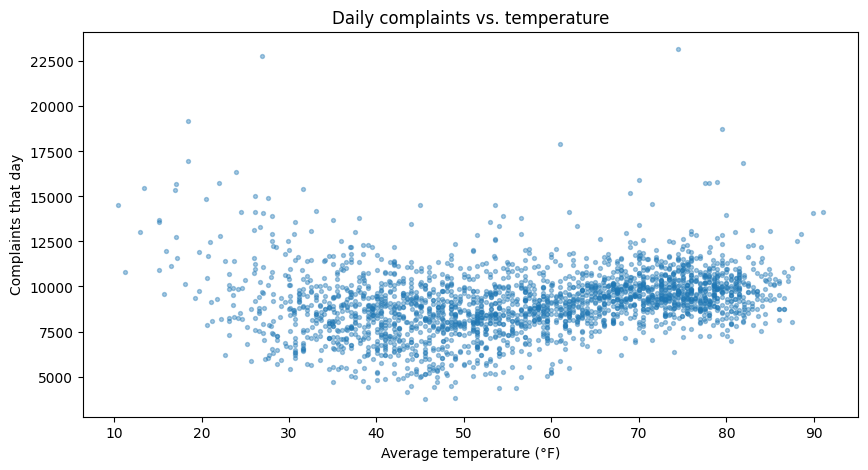

In [140]:
#One row per day: number of complaints and that day's Central Park weather
ComplaintType = "Problem (formerly Complaint Type)"
Daily = ComplaintsWeather.groupby("CREATED_DATE").agg(REQUESTS=("Unique Key", "size"), TAVG=("CP_TAVG", "first"),
                                                       PRCP=("CP_PRCP", "first"), SNOW=("CP_SNOW", "first"), SEASON=("SEASON", "first"))

#One row per day, one column per complaint type
DailyByType = ComplaintsWeather.groupby(["CREATED_DATE", ComplaintType]).size().unstack(fill_value=0)

#Average temperature vs. number of complaints, one dot per day
Daily.plot.scatter(x="TAVG", y="REQUESTS", s=8, alpha=0.4, figsize=(10, 5),
                   xlabel="Average temperature (°F)", ylabel="Complaints that day", title="Daily complaints vs. temperature")

SEASON  Problem (formerly Complaint Type)
Fall    Illegal Parking                      668028
        Noise - Residential                  631997
        HEAT/HOT WATER                       383085
Spring  Illegal Parking                      780566
        Noise - Residential                  623101
        HEAT/HOT WATER                       327485
Summer  Illegal Parking                      778384
        Noise - Residential                  704116
        Noise - Street/Sidewalk              523760
Winter  HEAT/HOT WATER                       877167
        Illegal Parking                      665107
        Noise - Residential                  578167
dtype: int64

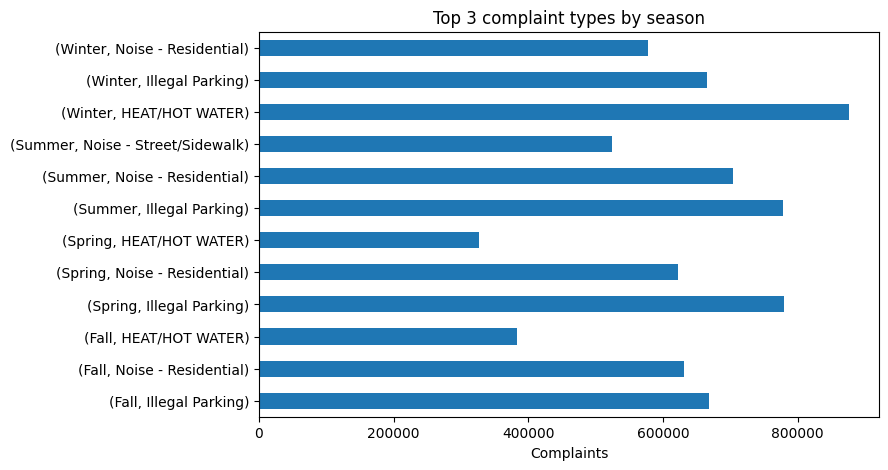

In [141]:
#Top 3 complaint types in each season
SeasonCounts = ComplaintsWeather.groupby(["SEASON", ComplaintType]).size()
TopBySeason = SeasonCounts.groupby(level="SEASON", group_keys=False).nlargest(3)
TopBySeason.plot.barh(figsize=(8, 5), ylabel="", xlabel="Complaints", title="Top 3 complaint types by season")
TopBySeason

<Axes: title={'center': 'Complaints that rise the most on rainy days'}, xlabel='Complaints per day'>

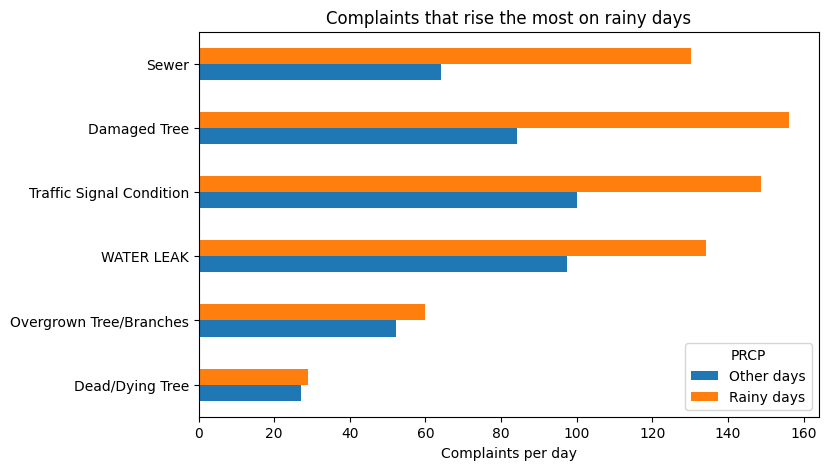

In [142]:
#Average complaints per day on rainy days (0.1 in or more) vs. other days, for the 6 types that rise the most
#Only types with at least 5 complaints a day are included
Rain = DailyByType.groupby(Daily["PRCP"] >= 0.1).mean().T.rename(columns={False: "Other days", True: "Rainy days"})
Rain = Rain[Rain["Other days"] >= 5]
Rain.loc[(Rain["Rainy days"] / Rain["Other days"]).nlargest(6).index[::-1]].plot.barh(ylabel="", figsize=(8, 5), xlabel="Complaints per day", title="Complaints that rise the most on rainy days")

<Axes: title={'center': 'Complaints that rise the most on snowy days'}, xlabel='Complaints per day'>

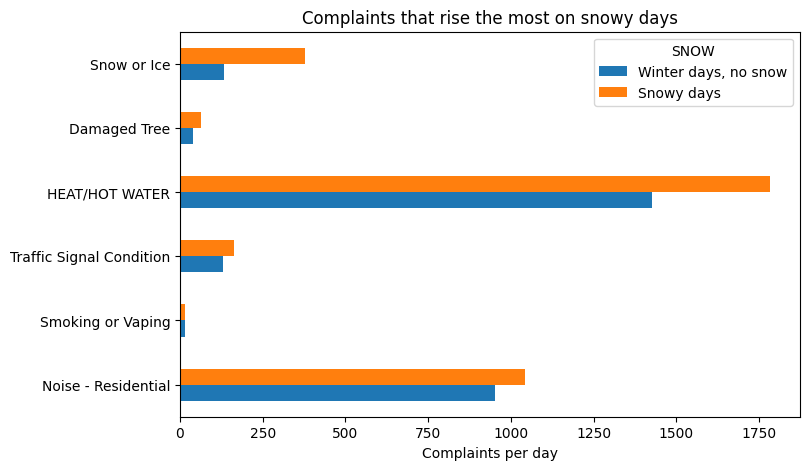

In [143]:
#Same comparison for snowy days, using winter days only so snowy days are compared with other winter days
Winter = Daily["SEASON"] == "Winter"
Snow = DailyByType[Winter].groupby(Daily.loc[Winter, "SNOW"] > 0).mean().T.rename(columns={False: "Winter days, no snow", True: "Snowy days"})
Snow = Snow[Snow["Winter days, no snow"] >= 5]
Snow.loc[(Snow["Snowy days"] / Snow["Winter days, no snow"]).nlargest(6).index[::-1]].plot.barh(ylabel="", figsize=(8, 5), xlabel="Complaints per day", title="Complaints that rise the most on snowy days")